# Predicción de la recuperación de oro

## Descripción del proyecto

Este proyecto desarrolla un prototipo de modelo de machine learning para **Zyfra**, empresa que crea soluciones de eficiencia para la industria pesada.

El modelo predice la cantidad de oro que se recupera del mineral a partir de los datos del proceso de extracción y purificación. Con esta predicción, la planta puede optimizar la producción y descartar los parámetros de operación que no son rentables.

## Objetivo

Predecir dos valores de recuperación de oro:

- `rougher.output.recovery`: recuperación en la etapa de flotación (rougher).
- `final.output.recovery`: recuperación en el concentrado final.

## Datos

- `gold_recovery_train.csv`: conjunto de entrenamiento.
- `gold_recovery_test.csv`: conjunto de prueba (sin las variables de salida del proceso).
- `gold_recovery_full.csv`: conjunto completo, del que se toman los valores reales de prueba.

## Métrica

Se usa el **sMAPE** (error porcentual absoluto medio simétrico), ponderado así:

sMAPE final = 25 % × sMAPE rougher + 75 % × sMAPE final

## Pasos

1. Cargar y preparar los datos: validar el cálculo de recuperación, revisar valores ausentes y variables que no están en prueba.
2. Analizar los datos: concentración de metales (Au, Ag, Pb) por etapa, distribución del tamaño de partícula y valores atípicos.
3. Construir y evaluar modelos con validación cruzada, y comparar el mejor contra un modelo de referencia (predecir el promedio).
4. Presentar conclusiones.

**Herramientas:** Python, pandas, NumPy, scikit-learn, Matplotlib.

# Importar librerías

In [2]:
#Librerías
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer

# 1. Cargue y preparación de datos

In [3]:
# Cargue de datos
recovery_train = pd.read_csv('/datasets/gold_recovery_train.csv')
recovery_test = pd.read_csv('/datasets/gold_recovery_test.csv')
recovery_full = pd.read_csv('/datasets/gold_recovery_full.csv')

In [4]:
print(recovery_train.head())
print(recovery_test.head())
print(recovery_full.head())

                  date  final.output.concentrate_ag  \
0  2016-01-15 00:00:00                     6.055403   
1  2016-01-15 01:00:00                     6.029369   
2  2016-01-15 02:00:00                     6.055926   
3  2016-01-15 03:00:00                     6.047977   
4  2016-01-15 04:00:00                     6.148599   

   final.output.concentrate_pb  final.output.concentrate_sol  \
0                     9.889648                      5.507324   
1                     9.968944                      5.257781   
2                    10.213995                      5.383759   
3                     9.977019                      4.858634   
4                    10.142511                      4.939416   

   final.output.concentrate_au  final.output.recovery  final.output.tail_ag  \
0                    42.192020              70.541216             10.411962   
1                    42.701629              69.266198             10.462676   
2                    42.657501              68.

### Comprobar cálculo de recuperación

In [5]:
# Cálculo de recovery
recovery_train['recovery'] = (recovery_train['rougher.output.concentrate_au'] * (recovery_train['rougher.input.feed_au'] - recovery_train['rougher.output.tail_au'])) / (recovery_train['rougher.input.feed_au'] * (recovery_train['rougher.output.concentrate_au'] - recovery_train['rougher.output.tail_au']))*100

# Para poder realizar el cálculo del EAM es necesario eliminar los datos en NaN 
recovery_train_clean = recovery_train[['rougher.output.recovery', 'recovery']].dropna()

mean_absolute_error(recovery_train_clean['rougher.output.recovery'], recovery_train_clean['recovery'])


9.303415616264301e-15

### Características no disponibles en conjunto de prueba

In [6]:
# Comparación de características conjunto de entrenamiento y conjunto de prueba
carac_train = set(recovery_train.columns)
carac_test = set(recovery_test.columns)

dif = carac_train - carac_test
print(dif)

{'primary_cleaner.output.concentrate_sol', 'primary_cleaner.output.concentrate_ag', 'rougher.output.tail_au', 'rougher.calculation.sulfate_to_au_concentrate', 'secondary_cleaner.output.tail_pb', 'rougher.output.recovery', 'secondary_cleaner.output.tail_ag', 'final.output.concentrate_pb', 'rougher.output.tail_sol', 'final.output.concentrate_ag', 'final.output.tail_ag', 'rougher.output.concentrate_pb', 'rougher.output.concentrate_ag', 'primary_cleaner.output.tail_au', 'final.output.concentrate_au', 'primary_cleaner.output.concentrate_pb', 'final.output.tail_au', 'secondary_cleaner.output.tail_sol', 'rougher.output.tail_pb', 'recovery', 'final.output.tail_sol', 'rougher.output.tail_ag', 'rougher.calculation.au_pb_ratio', 'final.output.tail_pb', 'primary_cleaner.output.tail_sol', 'rougher.calculation.floatbank11_sulfate_to_au_feed', 'secondary_cleaner.output.tail_au', 'primary_cleaner.output.tail_pb', 'primary_cleaner.output.concentrate_au', 'final.output.recovery', 'rougher.calculation.fl

son parámetros de salida (output) del proceso y cálculos derivados de esos resultados — es decir, datos que solo existen después de que el proceso de flotación ya ocurrió, por lo que no pueden conocerse de antemano y no están en el conjunto de prueba.

## Preprocesamiento de datos

In [7]:
nombres = ["recovery_train", "recovery_test", "recovery_full"]
datos = [recovery_train, recovery_test, recovery_full]

for nombre, data in zip(nombres, datos):
    print(f"\n{nombre}")
    print("Dimensiones:", data.shape)
    print("\nInformación general:")
    data.info()
    print("\nValores ausentes:")
    print(data.isna().sum())



recovery_train
Dimensiones: (16860, 88)

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16860 entries, 0 to 16859
Data columns (total 88 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   date                                                16860 non-null  object 
 1   final.output.concentrate_ag                         16788 non-null  float64
 2   final.output.concentrate_pb                         16788 non-null  float64
 3   final.output.concentrate_sol                        16490 non-null  float64
 4   final.output.concentrate_au                         16789 non-null  float64
 5   final.output.recovery                               15339 non-null  float64
 6   final.output.tail_ag                                16794 non-null  float64
 7   final.output.tail_pb                                16677 non-null  float64
 8   final.output.

### recovery_train

Eliminar filas con valores NaN ya que corresponden a menos del 1%, re calcular la columna recovery y pasar la columna date a formato de fecha


In [8]:
list_train_drop = [col for col in recovery_train.columns if col != 'recovery']

In [9]:
# Eliminar filas con valores NaN sin tener en ceunta la columna 'recovery'
recovery_train = recovery_train.dropna(
    subset = list_train_drop
).copy()

In [10]:
# Cálculo de la columna recovery

mask = recovery_train['recovery'].isna()

recovery_train.loc[mask, 'recovery'] = (recovery_train.loc[mask, 'rougher.output.concentrate_au'] * (recovery_train.loc[mask, 'rougher.input.feed_au'] - recovery_train.loc[mask, 'rougher.output.tail_au'])) / (recovery_train.loc[mask, 'rougher.input.feed_au'] * (recovery_train.loc[mask, 'rougher.output.concentrate_au'] - recovery_train.loc[mask, 'rougher.output.tail_au']))*100


In [11]:
recovery_train['recovery'].isna().sum()

0

In [12]:
# Cambiar formato a fecha de 'date'

recovery_train['date'] = pd.to_datetime(recovery_train['date'])




### recovery_test

Hay varias columnas con datos NaN con mas de un 5%, eliminar impactaria de manera significativa en la data por ello decido rellenar estos valores con la media.

Eliminar filas con valores NaN ya que corresponden a menos del 1% y pasar la columna date a formato de fecha




In [13]:
# crear lista para rellenar con media
lista_test = ['primary_cleaner.input.sulfate', 'primary_cleaner.input.depressant', 'rougher.input.floatbank10_sulfate', 'rougher.input.floatbank11_xanthate']

for col in lista_test:
    recovery_test[col] = recovery_test[col].fillna(recovery_test[col].mean())


recovery_test[lista_test].isna().sum()

primary_cleaner.input.sulfate         0
primary_cleaner.input.depressant      0
rougher.input.floatbank10_sulfate     0
rougher.input.floatbank11_xanthate    0
dtype: int64

In [14]:
list_test_drop = [col for col in recovery_test.columns.tolist() if col not in lista_test]

In [15]:
recovery_test = recovery_test.dropna(subset=list_test_drop).copy()

In [16]:
recovery_test.isna().sum()

date                                          0
primary_cleaner.input.sulfate                 0
primary_cleaner.input.depressant              0
primary_cleaner.input.feed_size               0
primary_cleaner.input.xanthate                0
primary_cleaner.state.floatbank8_a_air        0
primary_cleaner.state.floatbank8_a_level      0
primary_cleaner.state.floatbank8_b_air        0
primary_cleaner.state.floatbank8_b_level      0
primary_cleaner.state.floatbank8_c_air        0
primary_cleaner.state.floatbank8_c_level      0
primary_cleaner.state.floatbank8_d_air        0
primary_cleaner.state.floatbank8_d_level      0
rougher.input.feed_ag                         0
rougher.input.feed_pb                         0
rougher.input.feed_rate                       0
rougher.input.feed_size                       0
rougher.input.feed_sol                        0
rougher.input.feed_au                         0
rougher.input.floatbank10_sulfate             0
rougher.input.floatbank10_xanthate      

In [17]:
# Cambiar formato a fecha de 'date'

recovery_test['date'] = pd.to_datetime(recovery_test['date'])

### recovery_full

La columna 'final.output.concentrate_sol' cuenta con datos NaN con mas de un 1%,  por ello decido rellenar estos valores con la media.

Eliminar filas con valores NaN ya que corresponden a menos del 1% y pasar la columna date a formato de fecha


In [18]:
recovery_full['final.output.concentrate_sol'] = recovery_full['final.output.concentrate_sol'].fillna(recovery_full['final.output.concentrate_sol'].mean())

In [19]:
list_full_drop = [col for col in recovery_full.columns.tolist() if col != 'final.output.concentrate_sol']

In [20]:

recovery_full = recovery_full.dropna(subset=list_full_drop).copy()

recovery_full.isna().sum()


date                                          0
final.output.concentrate_ag                   0
final.output.concentrate_pb                   0
final.output.concentrate_sol                  0
final.output.concentrate_au                   0
                                             ..
secondary_cleaner.state.floatbank5_a_level    0
secondary_cleaner.state.floatbank5_b_air      0
secondary_cleaner.state.floatbank5_b_level    0
secondary_cleaner.state.floatbank6_a_air      0
secondary_cleaner.state.floatbank6_a_level    0
Length: 87, dtype: int64

In [21]:
# Cambiar formato a fecha de 'date'

recovery_full['date'] = pd.to_datetime(recovery_full['date'])

# 2. Análisis de datos

### Cambio en concentración de metales

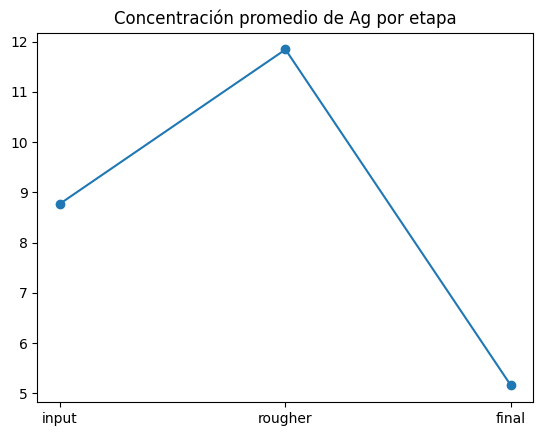

In [22]:
# Cálculo de medias y grafico para Ag

ag_input_mean = recovery_train['rougher.input.feed_ag'].mean()
ag_rougher_mean = recovery_train['rougher.output.concentrate_ag'].mean()
ag_final_mean = recovery_train['final.output.concentrate_ag'].mean()


etapas = ['input', 'rougher', 'final']
valores = [ag_input_mean, ag_rougher_mean, ag_final_mean]

plt.plot(etapas, valores, marker='o')
plt.title('Concentración promedio de Ag por etapa')
plt.show()


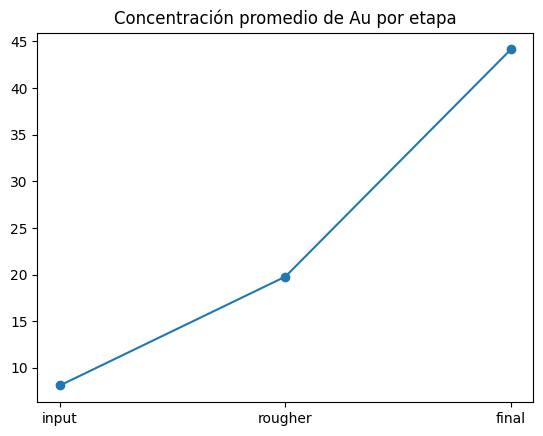

In [23]:

# Cálculo de medias y grafico para Au

au_input_mean = recovery_train['rougher.input.feed_au'].mean()
au_rougher_mean = recovery_train['rougher.output.concentrate_au'].mean()
au_final_mean = recovery_train['final.output.concentrate_au'].mean()


etapas = ['input', 'rougher', 'final']
valores = [au_input_mean, au_rougher_mean, au_final_mean]

plt.plot(etapas, valores, marker='o')
plt.title('Concentración promedio de Au por etapa')
plt.show()



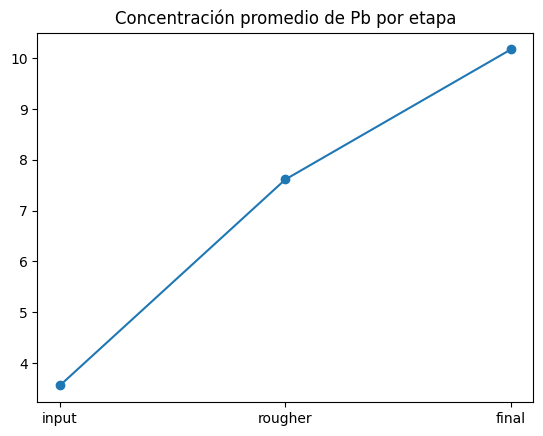

In [24]:
# Cálculo de medias y grafico para Pb

pb_input_mean = recovery_train['rougher.input.feed_pb'].mean()
pb_rougher_mean = recovery_train['rougher.output.concentrate_pb'].mean()
pb_final_mean = recovery_train['final.output.concentrate_pb'].mean()


etapas = ['input', 'rougher', 'final']
valores = [pb_input_mean, pb_rougher_mean, pb_final_mean]

plt.plot(etapas, valores, marker='o')
plt.title('Concentración promedio de Pb por etapa')
plt.show()



El metal Ag presenta un comportamiento diferente ya que en etapa de rougher aumenta pero luego al final disminuye; A diferencia de los metales Au y Pb que siempre estan aumentando.

## Distribuciones tamaños de particulas

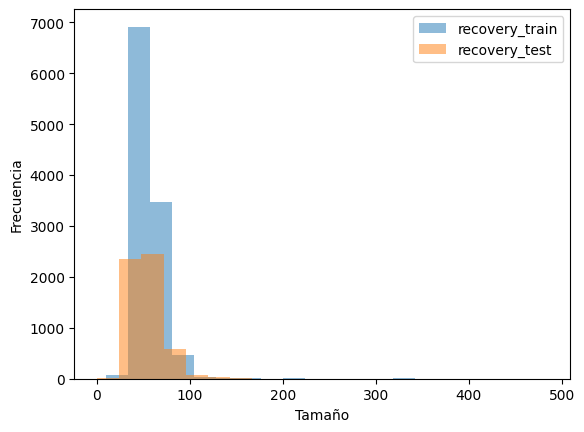

In [25]:
# Grafico de distribuciones de los tamaños
plt.hist(recovery_train['rougher.input.feed_size'], alpha=0.5, label='recovery_train', bins=20)
plt.hist(recovery_test['rougher.input.feed_size'], alpha=0.5, label='recovery_test', bins=20)
plt.xlabel('Tamaño')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()


Debido a que la distribución es similar tanto en el conjunto de entrenamiento como en el conjunto de prueba, podría decirse que si son comparables sus distribuciones.

## Concentraciones totales

In [26]:
# Suma de concentraciones

recovery_train['total_feed'] = recovery_train[['rougher.input.feed_ag',
    'rougher.input.feed_pb',
    'rougher.input.feed_sol',
   'rougher.input.feed_au']].sum(axis=1)


recovery_train['total_rougher'] = recovery_train[['rougher.output.concentrate_ag',
    'rougher.output.concentrate_pb',
    'rougher.output.concentrate_sol',
   'rougher.output.concentrate_au']].sum(axis=1)

recovery_train['total_final'] = recovery_train[['final.output.concentrate_ag',
    'final.output.concentrate_pb',
    'final.output.concentrate_sol',
   'final.output.concentrate_au']].sum(axis=1)


<AxesSubplot:>

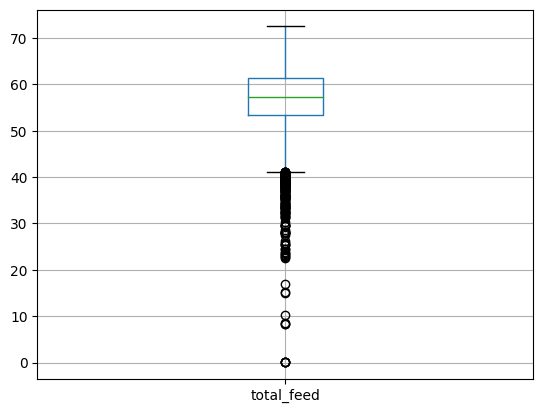

In [27]:
# Gráficos de caja
recovery_train.boxplot(column='total_feed')

<AxesSubplot:>

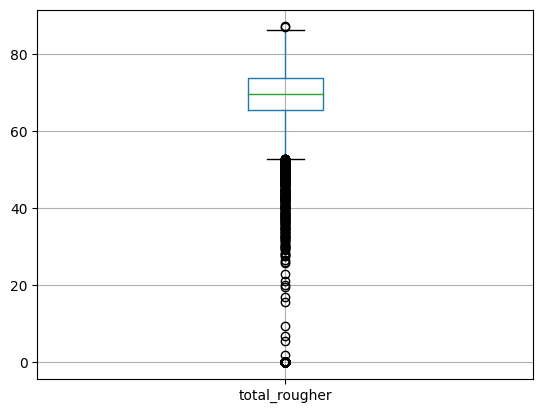

In [28]:
recovery_train.boxplot(column='total_rougher')

<AxesSubplot:>

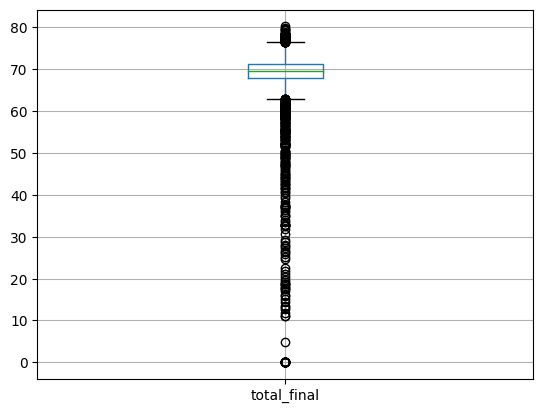

In [29]:
recovery_train.boxplot(column='total_final')

Se evidencian datos atípicos en las 3 sumas de las 3 etapas, los cuales pueden causar ruido a la data, por ello, decido eliminar estos datos.

In [30]:
recovery_train = recovery_train[(recovery_train['total_feed'] > 40) & (recovery_train['total_rougher'] > 52) & (recovery_train['total_final'] > 62)]

In [31]:

# Cálculo de total_feed para la data de prueba
recovery_test['total_feed'] = recovery_test[['rougher.input.feed_ag',
    'rougher.input.feed_pb',
    'rougher.input.feed_sol',
   'rougher.input.feed_au']].sum(axis=1)


recovery_test = recovery_test[(recovery_test['total_feed'] > 40)]

In [32]:
print(recovery_train.shape)
print(recovery_test.shape)

(10097, 91)
(5286, 54)


recovery_train: pasó de 16860 a 10097 filas (se eliminaron 6763 filas, un 40% aproximadamente).

recovery_test: pasó de 5856 a 5286 filas (se eliminaron 570 filas, un 10% aproximadamente).



# 3. Construir el modelo

## modelo sMAPE

In [33]:

# Funciones modelo sMAPE
def sMAPE(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    numerador = np.abs(y_true - y_pred)
    denominador = (np.abs(y_true) + np.abs(y_pred)) / 2

    ratio = np.divide(
        numerador,
        denominador,
        out=np.zeros_like(numerador, dtype=float),
        where=denominador != 0
    )

    return np.mean(ratio) * 100


def sMAPE_final(y_true_rougher, y_pred_rougher,
                y_true_final, y_pred_final):

    smape_rougher = sMAPE(y_true_rougher, y_pred_rougher)
    smape_final = sMAPE(y_true_final, y_pred_final)

    return 0.25 * smape_rougher + 0.75 * smape_final



## Modelos

In [34]:
# Variables objetivo
targets = ['rougher.output.recovery', 'final.output.recovery']

# Características: las disponibles en prueba, sin la fecha ni la suma auxiliar 'total_feed'
feature_columns = [c for c in recovery_test.columns if c not in ['date', 'total_feed']]

# Los objetivos de prueba están en recovery_full: se alinean por fecha
test_set = recovery_test.merge(recovery_full[['date'] + targets], on='date', how='inner')

X_train, y_train = recovery_train[feature_columns], recovery_train[targets]
X_test, y_test = test_set[feature_columns], test_set[targets]

print('Entrenamiento:', X_train.shape, y_train.shape)
print('Prueba:', X_test.shape, y_test.shape)

Entrenamiento: (10097, 52) (10097, 2)
Prueba: (5021, 52) (5021, 2)


In [35]:
# sMAPE final adaptado a salidas múltiples (col. 0 = rougher, col. 1 = final)
def smape_final_multi(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return sMAPE_final(y_true[:, 0], y_pred[:, 0], y_true[:, 1], y_pred[:, 1])

# Menor sMAPE es mejor, por eso greater_is_better=False (sklearn devuelve el valor negativo)
smape_scorer = make_scorer(smape_final_multi, greater_is_better=False)

# Los datos están ordenados en el tiempo: se usan bloques contiguos (sin mezclar)
cv = KFold(n_splits=5, shuffle=False)

def evaluar_cv(modelo):
    scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring=smape_scorer, n_jobs=-1)
    return -scores.mean()


In [36]:
# Modelos candidatos
def con_imputador(modelo):
    return make_pipeline(SimpleImputer(strategy='median'), modelo)

candidatos = {
    'Dummy (media)': DummyRegressor(strategy='mean'),
    'Regresión lineal': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression()),
}

for depth in [3, 5, 8, 12]:
    candidatos[f'Árbol (max_depth={depth})'] = con_imputador(
        DecisionTreeRegressor(max_depth=depth, random_state=12345))

for depth in [5, 10]:
    for n in [50, 100]:
        candidatos[f'Bosque (max_depth={depth}, n_est={n})'] = con_imputador(
            RandomForestRegressor(max_depth=depth, n_estimators=n, random_state=12345, n_jobs=-1))

# Validación cruzada
resultados_cv = pd.Series({nombre: evaluar_cv(modelo) for nombre, modelo in candidatos.items()},
                          name='sMAPE final (CV)').sort_values()
resultados_cv.to_frame()


,sMAPE final (CV)
"Bosque (max_depth=5, n_est=100)",7.817259
"Bosque (max_depth=5, n_est=50)",7.842629
"Bosque (max_depth=10, n_est=100)",8.019577
"Bosque (max_depth=10, n_est=50)",8.063158
Regresión lineal,8.202474
Árbol (max_depth=3),8.605384
Dummy (media),8.644589
Árbol (max_depth=5),9.690564
Árbol (max_depth=8),10.938447
Árbol (max_depth=12),11.781635


In [37]:
# Mejor modelo según validación cruzada
mejor_nombre = resultados_cv.idxmin()
print(f'Mejor modelo: {mejor_nombre} | sMAPE CV = {resultados_cv.min():.3f}')

# Prueba final: entrenar con todo el conjunto de entrenamiento y evaluar en prueba
def evaluar_en_prueba(modelo):
    pred = modelo.fit(X_train, y_train).predict(X_test)
    return {
        'sMAPE rougher': sMAPE(y_test.iloc[:, 0], pred[:, 0]),
        'sMAPE final': sMAPE(y_test.iloc[:, 1], pred[:, 1]),
        'sMAPE total': smape_final_multi(y_test, pred),
    }

comparacion_test = pd.DataFrame({
    mejor_nombre: evaluar_en_prueba(candidatos[mejor_nombre]),
    'Dummy (media)': evaluar_en_prueba(candidatos['Dummy (media)']),
}).T
comparacion_test


Mejor modelo: Bosque (max_depth=5, n_est=100) | sMAPE CV = 7.817


,sMAPE rougher,sMAPE final,sMAPE total
"Bosque (max_depth=5, n_est=100)",9.362492,8.446324,8.675366
Dummy (media),8.671893,8.272507,8.372353


## Conclusiones

Se evaluaron mediante validación cruzada de 5 bloques (métrica: sMAPE final, 25 % rougher + 75 % final) un modelo constante (Dummy), una regresión lineal, árboles de decisión de distinta profundidad y bosques aleatorios.

El mejor modelo en validación cruzada fue un bosque aleatorio (max_depth=5, n_estimators=100), con un sMAPE de 7.817.
Al probarlo en la muestra de prueba obtuvo un sMAPE total de 8.675 (rougher = 9.362, final = 8.446). El modelo constante obtuvo 8.372 (rougher = 8.672, final = 8.273).

El bosque aleatorio no mejora al modelo constante en prueba: es 0.30 puntos peor en el sMAPE total, y es peor en ambas etapas, especialmente en rougher.
El error en prueba (8.675) es mayor que el de validación cruzada (7.817), lo que indica que el modelo generaliza peor a datos nuevos de lo que sugería la validación.

En conclusión, con las características disponibles el modelo no demuestra capacidad predictiva superior a predecir el promedio. Se recomienda revisar la limpieza de datos, la distribución de las características entre entrenamiento y prueba, y probar otros enfoques antes de usarlo en producción.